In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [8]:
df = pd.read_csv("emails.csv")
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [ ]:
print(df.info())
print(df.shape)

(5172, 3002)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB
None


In [10]:
df.isnull().sum()

Email No.     0
the           0
to            0
ect           0
and           0
             ..
military      0
allowing      0
ff            0
dry           0
Prediction    0
Length: 3002, dtype: int64

In [11]:
df.drop(columns=['Email No.'], errors="ignore", inplace=True)
df.drop_duplicates(inplace=True)
df.dropna(inplace=True)

In [12]:
X = df.drop('Prediction', axis=1)
y = df['Prediction']

In [13]:
print("Dataset Shape:", df.shape)
print("Spam and Normal Email Count:")
print(y.value_counts())

Dataset Shape: (4631, 3001)
Spam and Normal Email Count:
Prediction
0    3170
1    1461
Name: count, dtype: int64


In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training data : ", X_train.shape)
print("Testing data : ", X_test.shape)

Training data :  (3704, 3000)
Testing data :  (927, 3000)


In [18]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [20]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
print("KNN Classifier Report : ")
print(classification_report(y_test, y_pred_knn))

KNN Classifier Report : 
              precision    recall  f1-score   support

           0       0.98      0.79      0.88       635
           1       0.68      0.96      0.80       292

    accuracy                           0.85       927
   macro avg       0.83      0.88      0.84       927
weighted avg       0.89      0.85      0.85       927



In [21]:
svm = SVC(kernel='linear')
svm.fit(X_train,y_train)
y_pred_svm = svm.predict(X_test)
print("SVM Classification Report : ")
print(classification_report(y_test, y_pred_svm))

SVM Classification Report : 
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       635
           1       0.88      0.92      0.90       292

    accuracy                           0.94       927
   macro avg       0.92      0.93      0.93       927
weighted avg       0.94      0.94      0.94       927



In [22]:
# KNN evaluation
knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn, zero_division=0)
knn_recall = recall_score(y_test, y_pred_knn, zero_division=0)
knn_f1 = f1_score(y_test, y_pred_knn, zero_division=0)

# SVM evaluation
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm, zero_division=0)
svm_recall = recall_score(y_test, y_pred_svm, zero_division=0)
svm_f1 = f1_score(y_test, y_pred_svm, zero_division=0)

# Comparison table
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "KNN": [knn_accuracy, knn_precision, knn_recall, knn_f1],
    "SVM": [svm_accuracy, svm_precision, svm_recall, svm_f1]
})

print(results.to_string(index=False))

   Metric      KNN      SVM
 Accuracy 0.846818 0.936354
Precision 0.682039 0.884488
   Recall 0.962329 0.917808
 F1 Score 0.798295 0.900840


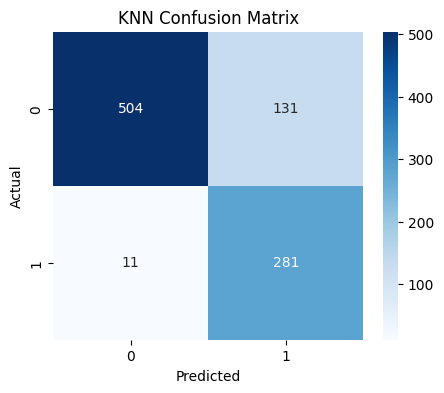

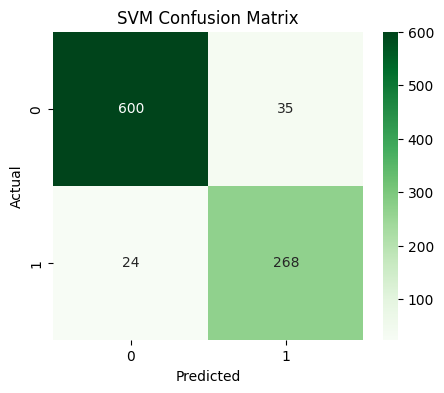

In [23]:
# KNN Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues")

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# SVM Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Greens")

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

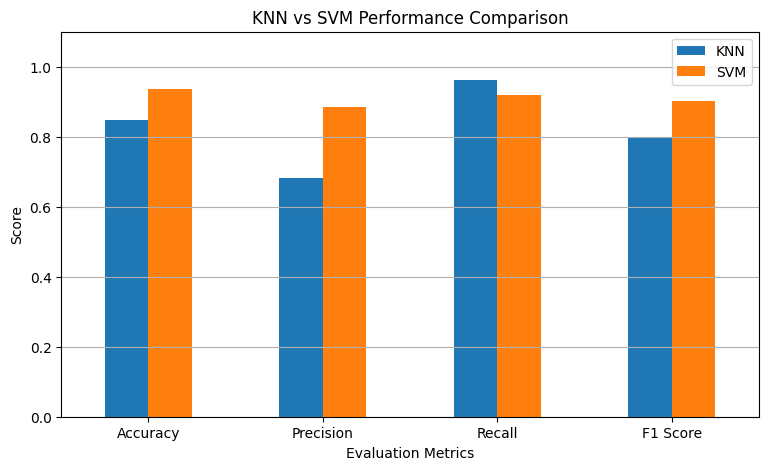

In [24]:
results_plot = results.set_index("Metric")

results_plot.plot(kind="bar", figsize=(9, 5))

plt.title("KNN vs SVM Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")
plt.show()